# Dome: shorter training histories and longer forward evaluation

This independent **exploratory** study preserves the completed final-test experiment. Models fit the first 14 or 28 calendar days and remain frozen during subsequent development evaluation. The primary comparison uses identical 11 November 2025?8 January 2026 windows, N=3; N=5 is secondary.

Targets describe opportunity occurrence and peak displayed basket margin. They do not describe execution P&L. Development results have been inspected previously, so these are not new untouched-test estimates.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
import torch
from IPython.display import display, Image
from threadpoolctl import threadpool_limits
ROOT=Path.cwd()
if not (ROOT/'src').exists(): ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
from src.common import sha256
from src.models.validation_horizon import run
from src.reporting.validation_horizon import analyze, verify, LABELS
RESULTS=ROOT/'results/validation_horizon'
torch.set_num_threads(4)
with threadpool_limits(limits=4):
    design=verify(RESULTS)
manifest=json.loads((RESULTS/'analysis/manifest.json').read_text())
assert manifest['study_completion_sha256']==sha256(RESULTS/'complete.json')
assert manifest['reporter_sha256']==sha256(ROOT/'src/reporting/validation_horizon.py')
for name,digest in manifest['files_sha256'].items():
    assert sha256(RESULTS/'analysis'/name)==digest,name
display(pd.read_csv(RESULTS/'populations.csv'))
display(pd.read_csv(RESULTS/'analysis/common_population.csv'))

,origin,population,rows,events,first,last,scheduled_hours,known,positive,unknown,positive_events,maximum_candidates,median_candidates,competitive_hours_n3
0,train_14d,training,3770,17,2025-10-14 20:00:00+00:00,2025-10-27 22:00:00+00:00,NaN,3770,39,0,7,14,12.0,314
1,train_14d,full_forward,22322,45,2025-10-28 00:00:00+00:00,2026-01-07 23:00:00+00:00,1728.0,18046,415,4276,11,19,14.0,1720
2,train_14d,common_forward,17293,41,2025-11-11 00:00:00+00:00,2026-01-07 23:00:00+00:00,NaN,14162,343,3131,11,19,12.5,1384
3,train_28d,training,7652,25,2025-10-14 20:00:00+00:00,2025-11-10 22:00:00+00:00,NaN,7652,110,0,10,15,12.0,650
4,train_28d,full_forward,17293,41,2025-11-11 00:00:00+00:00,2026-01-07 23:00:00+00:00,1392.0,14162,343,3131,11,19,12.5,1384
5,train_28d,common_forward,17293,41,2025-11-11 00:00:00+00:00,2026-01-07 23:00:00+00:00,NaN,14162,343,3131,11,19,12.5,1384


,origin,scheduled_hours,nonempty_hours,events,positive_hours,known_hours,unknown_hours,peak_value_sum
0,train_14d,1392,1392,41,343,14162,3131,8753.68714
1,train_28d,1392,1392,41,343,14162,3131,8753.68714


## Refit and reproduce, optionally

Default execution reads and verifies saved results. Set `RUN_STUDY=True` to create new fits in a fresh directory. This uses the saved Dome opportunity dataset and event metadata, makes no HTTP calls, and does not load original final-period outcomes. It may take several minutes.

Classical occurrence models use the same 33 book features. The two-stage forest and TabM use the same 36 combined features. TabM averages three seed-specific probability ? positive-value predictions, with 32 implicit members per stage. Epoch selection uses earlier training-only windows; classical settings are the original fixed configurations. The ensemble gives equal weight to within-scan ranks from logistic, occurrence forest and TabM.

In [2]:
RUN_STUDY=False
if RUN_STUDY:
    destination=ROOT/'results/runs/validation_horizon_reproduction'
    with threadpool_limits(limits=4):
        run(destination,device='cpu')
        analyze(destination)

## Selection pressure and primary results

Every eligible event competes before labels are consulted. Unknown outcomes consume slots and remain missing. Recall is selected known positive event-hours divided by all known positive event-hours. Value capture weights these hours by their maximum displayed one-basket margin, not collectible profit. Compare training histories on `common_forward`, because their full forward intervals differ.

,origin,model,top_n,positive_windows,captured_positive_windows,recall,peak_value_recall,selected_unknown_fraction,competitive_windows
18,train_14d,depth_rule,3,343,169,0.492711,0.918464,0.157088,1384
20,train_14d,fixed_book_logistic,3,343,290,0.845481,0.954910,0.003831,1384
22,train_14d,fixed_book_random_forest,3,343,293,0.854227,0.986859,0.162117,1384
24,train_14d,fixed_book_xgboost,3,343,267,0.778426,0.791312,0.195402,1384
26,train_14d,forest_two_stage,3,343,255,0.743440,0.849823,0.242337,1384
28,train_14d,freshness_rule,3,343,245,0.714286,0.951623,0.003592,1384
30,train_14d,quoted_gap_rule,3,343,248,0.723032,0.603785,0.227011,1384
32,train_14d,rank_ensemble,3,343,322,0.938776,0.997424,0.029215,1384
34,train_14d,tabm_two_stage,3,343,313,0.912536,0.976405,0.046935,1384
54,train_28d,depth_rule,3,343,169,0.492711,0.918464,0.157088,1384


,origin,model,top_n,positive_windows,captured_positive_windows,recall,peak_value_recall,selected_unknown_fraction,competitive_windows
19,train_14d,depth_rule,5,343,225,0.655977,0.932744,0.237928,1197
21,train_14d,fixed_book_logistic,5,343,339,0.988338,0.999993,0.025461,1197
23,train_14d,fixed_book_random_forest,5,343,325,0.947522,0.991699,0.159789,1197
25,train_14d,fixed_book_xgboost,5,343,309,0.900875,0.982482,0.172520,1197
27,train_14d,forest_two_stage,5,343,312,0.909621,0.989212,0.178227,1197
29,train_14d,freshness_rule,5,343,307,0.895044,0.995247,0.013316,1197
31,train_14d,quoted_gap_rule,5,343,320,0.932945,0.984325,0.162716,1197
33,train_14d,rank_ensemble,5,343,339,0.988338,0.999708,0.078724,1197
35,train_14d,tabm_two_stage,5,343,335,0.976676,0.999034,0.115159,1197
55,train_28d,depth_rule,5,343,225,0.655977,0.932744,0.237928,1197


,origin,expected_random_recall,expected_random_value_capture
2,train_14d,0.198554,0.184175
6,train_28d,0.198554,0.184175


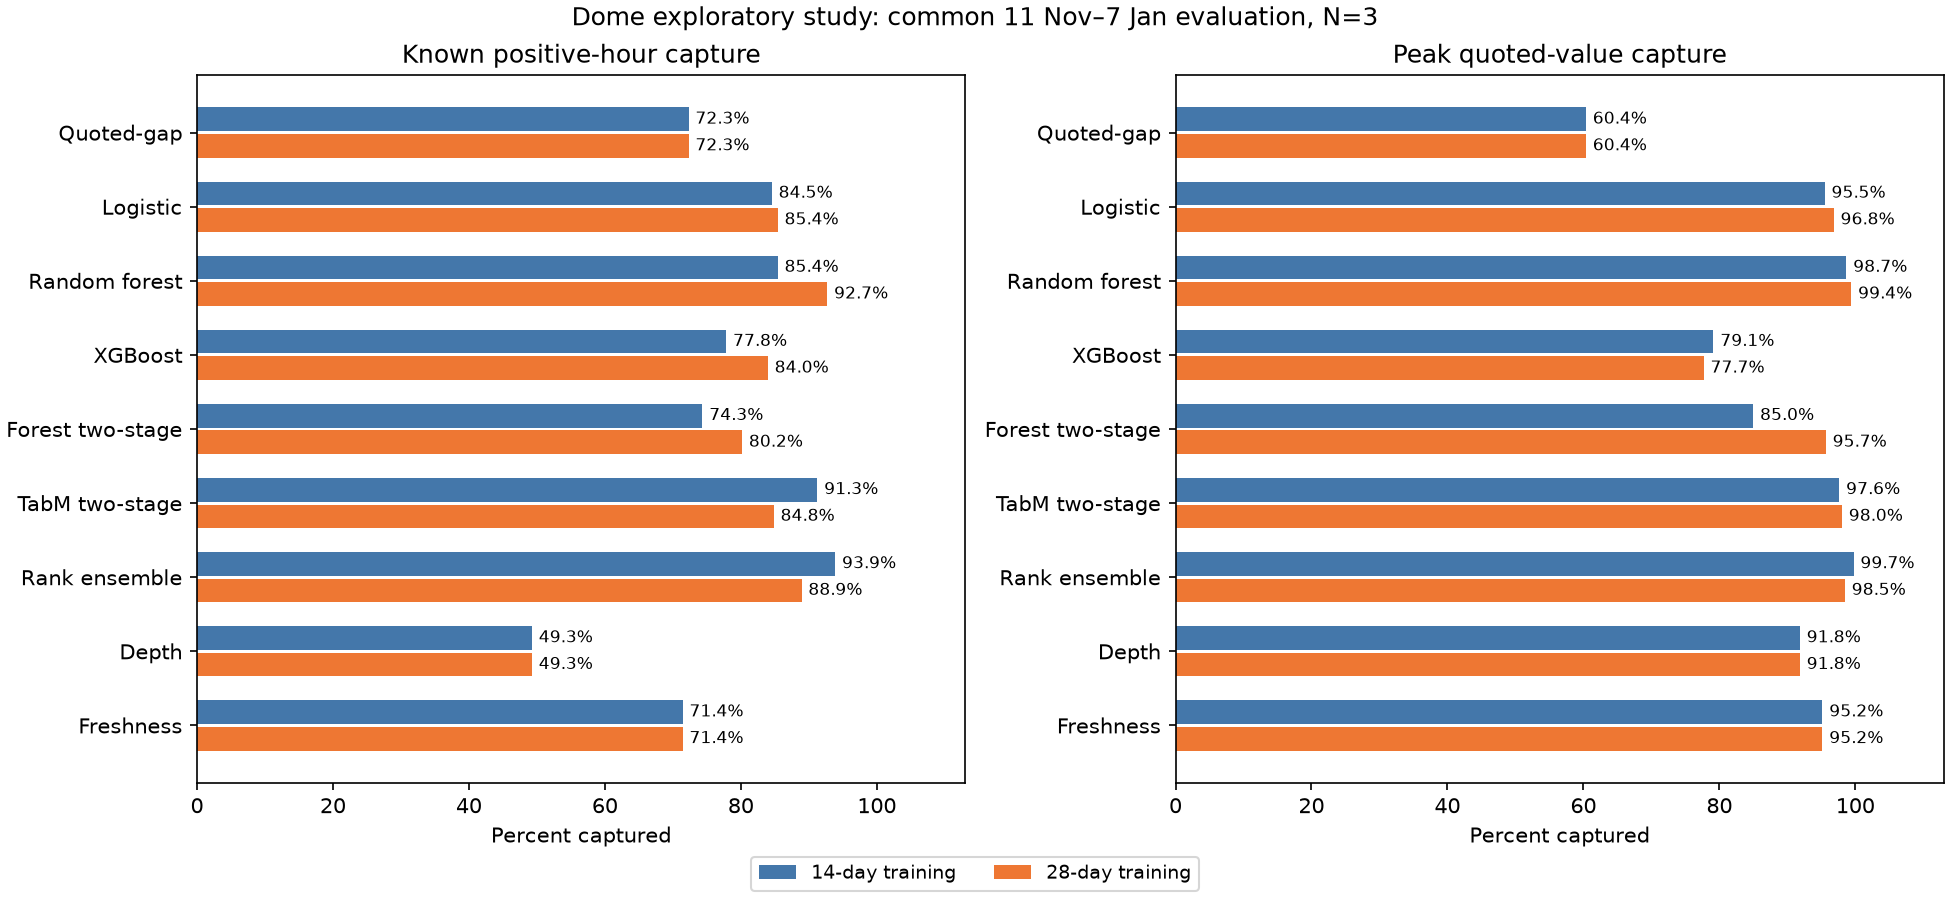

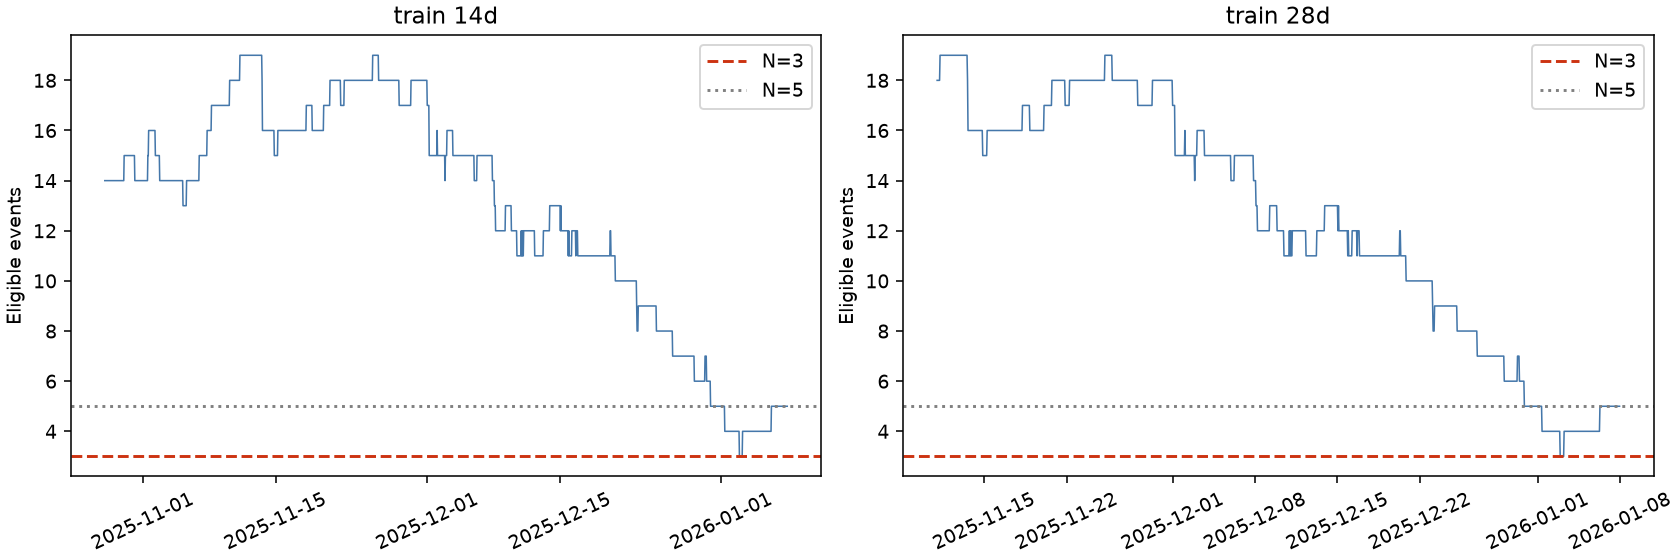

In [3]:
metrics=pd.read_csv(RESULTS/'metrics.csv')
columns=['origin','model','top_n','positive_windows','captured_positive_windows','recall','peak_value_recall','selected_unknown_fraction','competitive_windows']
for n in (3,5):
    display(metrics.loc[metrics.scope.eq('common_forward')&metrics.top_n.eq(n),columns])
display(pd.read_csv(RESULTS/'random_reference.csv').query("scope=='common_forward' and top_n==3")
    [['origin','expected_random_recall','expected_random_value_capture']])
display(Image(filename=str(RESULTS/'analysis/primary_capture.png')))
display(Image(filename=str(RESULTS/'analysis/candidate_pool.png')))

## Stability and concentration

Paired seven-day block intervals resample the same periods for each model and quoted-gap. They condition on fixed fits and the observed cohort; only nine blocks are available, the last is shorter, and there is no correction for examining multiple policies. They do not cover refitting uncertainty, missing outcomes, event selection or dependence beyond a block.

The December Fed sensitivity removes that event and **reranks** the remaining pool. Event contributions show how concentrated the quoted-value denominator is. Different feature views and learning targets mean this is a strategy comparison, not a pure architecture benchmark.

In [4]:
intervals=pd.read_csv(RESULTS/'paired_intervals.csv')
display(intervals.loc[intervals.top_n.eq(3),['origin','model','seven_day_blocks','recall_difference','recall_lower95','recall_upper95','value_capture_difference','value_capture_lower95','value_capture_upper95']])
display(pd.read_csv(RESULTS/'analysis/exclude_december_fed.csv')
    [['origin','model','positive_windows','recall','peak_value_recall']])
contributions=pd.read_csv(RESULTS/'analysis/event_capture.csv')
reference=contributions.loc[contributions.origin.eq('train_14d')&contributions.model.eq('quoted_gap_rule')]
display(reference.sort_values('peak_value',ascending=False).head(12))
display(pd.read_csv(RESULTS/'monthly_metrics.csv').query("scope=='common_forward' and top_n==3")
    [['origin','month','model','positive_windows','recall','peak_value_recall']])
display(json.loads((RESULTS/'analysis/preservation.json').read_text()))

,origin,model,seven_day_blocks,recall_difference,recall_lower95,recall_upper95,value_capture_difference,value_capture_lower95,value_capture_upper95
0,train_14d,depth_rule,9,-0.230321,-0.460617,-0.108264,0.314678,-0.314218,0.557704
2,train_14d,fixed_book_logistic,9,0.122449,-0.069841,0.235650,0.351125,-0.085157,0.572063
4,train_14d,fixed_book_random_forest,9,0.131195,0.019608,0.203742,0.383074,0.003891,0.593629
6,train_14d,fixed_book_xgboost,9,0.055394,-0.074084,0.133338,0.187526,-0.000672,0.259610
8,train_14d,forest_two_stage,9,0.020408,-0.064869,0.066508,0.246038,-0.000865,0.426145
10,train_14d,freshness_rule,9,-0.008746,-0.181818,0.101192,0.347838,-0.121369,0.578219
12,train_14d,quoted_gap_rule,9,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
14,train_14d,rank_ensemble,9,0.215743,0.077619,0.301951,0.393638,0.033175,0.601756
16,train_14d,tabm_two_stage,9,0.189504,0.056221,0.276766,0.372620,0.032358,0.600858
18,train_28d,depth_rule,9,-0.230321,-0.460617,-0.108264,0.314678,-0.314218,0.557704


,origin,model,positive_windows,recall,peak_value_recall
0,train_14d,depth_rule,247,0.319838,0.494933
1,train_14d,fixed_book_logistic,247,0.910931,0.995572
2,train_14d,fixed_book_random_forest,247,0.838057,0.920811
3,train_14d,fixed_book_xgboost,247,0.793522,0.889087
4,train_14d,forest_two_stage,247,0.777328,0.864777
5,train_14d,freshness_rule,247,0.732794,0.893493
6,train_14d,quoted_gap_rule,247,0.801619,0.876636
7,train_14d,rank_ensemble,247,0.959514,0.995830
8,train_14d,tabm_two_stage,247,0.931174,0.982737
9,train_28d,depth_rule,247,0.319838,0.494933


,origin,model,event_slug,positives,captured,peak_value,captured_value
268,train_14d,quoted_gap_rule,fed-decision-in-december,96,59,7349.36237,4065.66206
269,train_14d,quoted_gap_rule,fed-decision-in-january,135,112,827.41321,795.26897
272,train_14d,quoted_gap_rule,honduras-presidential-election,38,21,457.66625,327.39014
247,train_14d,quoted_gap_rule,avatar-fire-and-ash-opening-weekend-box-office,34,23,56.22870,39.16605
248,train_14d,quoted_gap_rule,boxing-jake-paul-vs-anthony-joshua-third-optio...,9,9,36.51982,36.51982
273,train_14d,quoted_gap_rule,largest-company-end-of-november,6,5,12.91743,10.82211
285,train_14d,quoted_gap_rule,which-party-holds-the-most-seats-after-argenti...,3,1,7.63683,5.45702
284,train_14d,quoted_gap_rule,which-company-has-the-best-ai-model-end-of-jan...,8,6,3.42800,2.63600
271,train_14d,quoted_gap_rule,gensyn-public-sale-total-commitments,7,7,2.23300,2.23300
274,train_14d,quoted_gap_rule,monad-market-cap-fdv-one-day-after-launch,6,4,0.16600,0.07800


,origin,month,model,positive_windows,recall,peak_value_recall
72,train_14d,2025-11,depth_rule,226,0.464602,0.922305
73,train_14d,2025-12,depth_rule,116,0.543103,0.880037
74,train_14d,2026-01,depth_rule,1,1.000000,1.000000
78,train_14d,2025-11,fixed_book_logistic,226,0.858407,0.961736
79,train_14d,2025-12,fixed_book_logistic,116,0.818966,0.886677
80,train_14d,2026-01,fixed_book_logistic,1,1.000000,1.000000
84,train_14d,2025-11,fixed_book_random_forest,226,0.827434,0.987564
85,train_14d,2025-12,fixed_book_random_forest,116,0.905172,0.979811
86,train_14d,2026-01,fixed_book_random_forest,1,1.000000,1.000000
90,train_14d,2025-11,fixed_book_xgboost,226,0.747788,0.773161


{'original_files_checked': 2913,
 'original_files_unchanged': True,
 'new_study_added': True,
 'original_final_protocol_replaced': False}

## Interpretation

The earlier evaluation contains more competing events than the completed final period and can distinguish these policies. Performance changes with training history; the best policy in one exploratory interval is not established as the best for generic Polymarket markets. Shorter training is a sensitivity analysis, not a way to guarantee separation or significance.

No new economic replay is included. The separate primary execution scenario remains 100 ms total source-update-to-order-arrival delay, uncapped capital/shares and displayed-depth limits. Peak quote-value capture must not be reported as trading P&L.

See [the report](../docs/reports/dome_validation_horizon.md) for findings and scope.